# Projeto 1 — Análise da população dos municípios brasileiros

Vamos consultar a API do SIDRA. A consulta abaixo seleciona a tabela 4709, o nível municipal, a variável 93 e o período 2022. A API permite recuperar os dados em formato JSON

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Pastas do projeto
PASTA = Path("..")
PASTA_DATA = PASTA / "data"
PASTA_FIGURES = PASTA / "figures"
PASTA_OUTPUTS = PASTA / "outputs"

for pasta in [PASTA_DATA, PASTA_FIGURES, PASTA_OUTPUTS]:
    pasta.mkdir(parents=True, exist_ok=True)

# Consulta ao SIDRA/IBGE
url = (
    "https://apisidra.ibge.gov.br/values/"
    "t/4709/n6/all/v/93/p/2022"
)

resposta = requests.get(url, timeout=60)
resposta.raise_for_status()

dados = resposta.json()

# O primeiro registro contém os nomes dos campos.
df = pd.DataFrame(dados[1:])

print("Dimensões:", df.shape)
print("Colunas:", df.columns.tolist())
display(df.head())

Dimensões: (5570, 11)
Colunas: ['NC', 'NN', 'MC', 'MN', 'V', 'D1C', 'D1N', 'D2C', 'D2N', 'D3C', 'D3N']


,NC,NN,MC,MN,V,D1C,D1N,D2C,D2N,D3C,D3N
0,6,Município,45,Pessoas,21494,1100015,Alta Floresta D'Oeste - RO,93,População residente,2022,2022
1,6,Município,45,Pessoas,96833,1100023,Ariquemes - RO,93,População residente,2022,2022
2,6,Município,45,Pessoas,5351,1100031,Cabixi - RO,93,População residente,2022,2022
3,6,Município,45,Pessoas,86887,1100049,Cacoal - RO,93,População residente,2022,2022
4,6,Município,45,Pessoas,15890,1100056,Cerejeiras - RO,93,População residente,2022,2022


Etapa 2 — Limpar e preparar os dados
Antes de analisar os dados, precisamos saber quais colunas correspondem ao município e à população.

In [2]:
print(df.columns.tolist())
display(df.head(3))

['NC', 'NN', 'MC', 'MN', 'V', 'D1C', 'D1N', 'D2C', 'D2N', 'D3C', 'D3N']


,NC,NN,MC,MN,V,D1C,D1N,D2C,D2N,D3C,D3N
0,6,Município,45,Pessoas,21494,1100015,Alta Floresta D'Oeste - RO,93,População residente,2022,2022
1,6,Município,45,Pessoas,96833,1100023,Ariquemes - RO,93,População residente,2022,2022
2,6,Município,45,Pessoas,5351,1100031,Cabixi - RO,93,População residente,2022,2022


In [3]:
# Selecionar as colunas necessárias
populacao = df[["D1C", "D1N", "V"]].copy()

# Renomear para nomes mais claros
populacao.columns = [
    "codigo_municipio",
    "municipio",
    "populacao"
]

# Converter a população para número
populacao["populacao"] = pd.to_numeric(
    populacao["populacao"],
    errors="coerce"
)

# Remover registros incompletos e duplicados
populacao = populacao.dropna(
    subset=["municipio", "populacao"]
)

populacao = populacao.drop_duplicates(
    subset=["codigo_municipio"]
)

# Manter valores populacionais válidos
populacao = populacao[
    populacao["populacao"] >= 0
].copy()

populacao["populacao"] = populacao["populacao"].astype(int)

print("Total de registros:", len(populacao))
display(populacao.head())

Total de registros: 5570


,codigo_municipio,municipio,populacao
0,1100015,Alta Floresta D'Oeste - RO,21494
1,1100023,Ariquemes - RO,96833
2,1100031,Cabixi - RO,5351
3,1100049,Cacoal - RO,86887
4,1100056,Cerejeiras - RO,15890


In [4]:
# Quantidade de municípios na base
total_municipios = populacao["codigo_municipio"].nunique()

# Estatísticas descritivas
estatisticas = populacao["populacao"].describe()

print("Municípios únicos:", total_municipios)
print("\nEstatísticas da população:")
display(estatisticas)

# Dez municípios mais populosos
top_10 = populacao.sort_values(
    by="populacao",
    ascending=False
).head(10)

display(top_10)

Municípios únicos: 5570

Estatísticas da população:


count    5.570000e+03
mean     3.645974e+04
std      2.065187e+05
min      8.330000e+02
25%      5.228000e+03
50%      1.106500e+04
75%      2.442725e+04
max      1.145200e+07
Name: populacao, dtype: float64

,codigo_municipio,municipio,populacao
3829,3550308,São Paulo - SP,11451999
3242,3304557,Rio de Janeiro - RJ,6211223
5569,5300108,Brasília - DF,2817381
949,2304400,Fortaleza - CE,2428708
2162,2927408,Salvador - BA,2417678
2309,3106200,Belo Horizonte - MG,2315560
111,1302603,Manaus - AM,2063689
4005,4106902,Curitiba - PR,1773718
1596,2611606,Recife - PE,1488920
5417,5208707,Goiânia - GO,1437366


In [5]:
maior = populacao["populacao"].max()
menor = populacao["populacao"].min()

print("Maior população:", maior)
print("Menor população:", menor)
print("Diferença:", maior - menor)

Maior população: 11451999
Menor população: 833
Diferença: 11451166


# Gráfico profissional
Vamos criar um gráfico de barras horizontais com os dez municípios mais populosos.

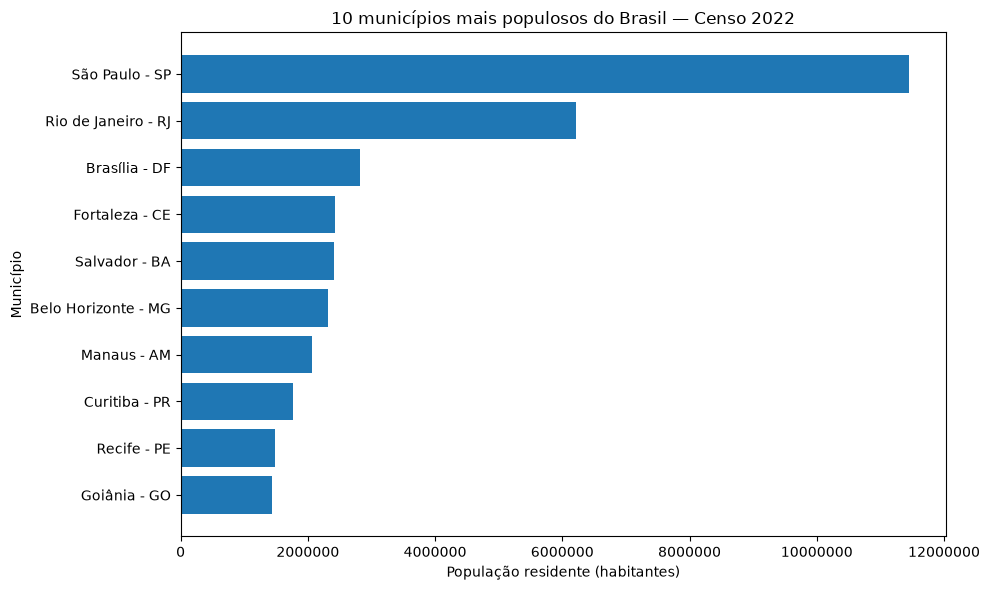

In [6]:
# Inverter a ordem para o maior ficar no topo
grafico = top_10.sort_values(
    by="populacao",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    grafico["municipio"],
    grafico["populacao"]
)

plt.title(
    "10 municípios mais populosos do Brasil — Censo 2022"
)

plt.xlabel("População residente (habitantes)")
plt.ylabel("Município")

plt.ticklabel_format(
    axis="x",
    style="plain"
)

plt.tight_layout()

# Salvar a imagem para o GitHub
plt.savefig(
    PASTA_FIGURES / "top_10_municipios.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Etapa  : Exportar os resultados
Salve a tabela dos dez municípios mais populosos em CSV:

In [7]:
top_10.to_csv(
    PASTA_OUTPUTS / "top_10_municipios.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Tabela exportada com sucesso!")

Tabela exportada com sucesso!


In [8]:
primeiro = top_10.iloc[0]
ultimo_top_10 = top_10.iloc[-1]

print("CONCLUSÕES DA ANÁLISE")
print("-" * 35)

print(
    f"A base contém {total_municipios:,} municípios."
)

print(
    f"O município mais populoso da base é "
    f"{primeiro['municipio']}, com "
    f"{primeiro['populacao']:,} habitantes."
)

print(
    f"A mediana da população é de "
    f"{mediana:,.0f} habitantes."
)

print(
    f"A população do décimo município no ranking "
    f"é de {ultimo_top_10['populacao']:,} habitantes."
)

CONCLUSÕES DA ANÁLISE
-----------------------------------
A base contém 5,570 municípios.
O município mais populoso da base é São Paulo - SP, com 11,451,999 habitantes.


NameError: name 'mediana' is not defined